<a href="https://colab.research.google.com/github/scalabrinig/cdProjetoAplicadoIV/blob/master/projeto/cd_projeto_aplicado_IV_doc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  <img src="https://raw.githubusercontent.com/scalabrinig/cdProjetoAplicadoIV/d093146488f56dfcf0ef286bcee8efe0e71b9c76/figuras/mackenzie_logo.jpg" width="25%" align="right"/>

# **PROJETO APLICADO IV - Ciência de Dados EaD - 2026/02**


# **Documentação do Projeto**

---

# **Título do Projeto**

## Análise Preditiva de Casos de Dengue em São Paulo para Apoio às Ações de Saúde Pública

---


In [ ]:
#@title **Identificação do Grupo**

#@markdown Integrantes do Grupo, nome completo em ordem alfabética (*informe: \<nome\>, \<matrícula\>*)
Aluno1 = 'Ândria Giovana Oliveira Cabeça da Silva, 10441204' #@param {type:"string"}
Aluno2 = 'Beatriz Ribeiro Porto Liberato, 10441384' #@param {type:"string"}
Aluno3 = 'Dalicio Pereira de Novaes Junior, 10441535' #@param {type:"string"}
Aluno4 = 'Gustavo da Conceição Guimarães, 10723830' #@param {type:"string"}
Aluno5 = 'Pedro Lima da Silva Junior, 10729027' #@param {type:"string"}


# **Resumo**

A dengue constitui um relevante problema de saúde pública no Brasil, apresentando comportamento temporal influenciado por fatores epidemiológicos, ambientais e climáticos. Este projeto tem como objetivo desenvolver uma solução analítica preditiva capaz de auxiliar na antecipação de períodos de aumento da incidência de dengue nos municípios do estado de São Paulo. Para isso, são utilizados dados epidemiológicos e climáticos disponibilizados pelo InfoDengue, organizados em séries temporais semanais. A metodologia contempla aquisição dos dados, análise exploratória, pré-processamento, caracterização de tendência e sazonalidade, construção de modelos preditivos e avaliação de desempenho. O recorte geográfico considera exclusivamente municípios paulistas e, nesta etapa, a modelagem utiliza uma série semanal agregada do estado como prova de conceito. São implementados um modelo sazonal de referência, um modelo estatístico SARIMA e um modelo de aprendizado de máquina baseado em Random Forest com variáveis defasadas. O desempenho é avaliado por meio das métricas MAE, RMSE e MASE. Os resultados quantitativos são produzidos automaticamente pelas células de modelagem do notebook a partir da base extraída do InfoDengue.


# **Introdução**

A dengue representa um importante desafio para a saúde pública brasileira, especialmente em regiões que apresentam condições ambientais e climáticas favoráveis à proliferação do mosquito *Aedes aegypti*. No estado de São Paulo, a recorrência de períodos de aumento da transmissão reforça a necessidade de estratégias capazes não apenas de acompanhar os casos registrados, mas também de antecipar cenários de maior incidência.

Nesse contexto, técnicas de Ciência de Dados e análise de séries temporais podem transformar registros epidemiológicos em informações úteis ao planejamento de ações de prevenção e controle. A identificação de padrões temporais, tendências, sazonalidades e relações entre a ocorrência da doença e variáveis climáticas pode contribuir para uma atuação mais preventiva por parte dos gestores públicos.

O projeto utiliza dados disponibilizados pelo InfoDengue, com apoio da API de localidades do Instituto Brasileiro de Geografia e Estatística (IBGE) para identificação dos municípios. A base possui registros organizados por semana epidemiológica e inclui, entre outras informações, casos notificados e estimados, incidência, número reprodutivo, população, temperatura e umidade.

O objetivo geral é desenvolver um produto analítico preditivo, fundamentado em séries temporais e Aprendizado de Máquina, para auxiliar na antecipação de períodos de aumento da incidência de dengue nos municípios do estado de São Paulo.

Como objetivos específicos, pretende-se:

- obter, estruturar e analisar dados epidemiológicos e climáticos dos municípios paulistas;
- avaliar a qualidade da base, identificando valores ausentes, duplicidades, inconsistências e possíveis valores atípicos;
- caracterizar o comportamento temporal dos casos de dengue, identificando tendência e sazonalidade;
- construir e avaliar modelos preditivos aplicáveis à série temporal;
- comparar os modelos por métricas de erro adequadas ao problema;
- manter uma solução executável e reproduzível que possa ser refinada na etapa final do projeto.

A realização do projeto justifica-se pela possibilidade de utilizar dados já disponíveis para apoiar decisões preventivas. A antecipação de períodos de crescimento da transmissão pode contribuir para o planejamento da rede de atendimento, organização de medicamentos e insumos e direcionamento de campanhas. O trabalho também se relaciona ao Objetivo de Desenvolvimento Sustentável 3 (ODS 3) — Saúde e Bem-Estar.


# **Referencial Teórico**

A análise de séries temporais investiga observações organizadas ao longo do tempo, considerando a dependência temporal entre seus valores. Entre os componentes frequentemente analisados estão tendência, sazonalidade e autocorrelação. Segundo Hyndman e Athanasopoulos (2021), reconhecer esses padrões é fundamental para a seleção de métodos adequados de previsão.

Entre as abordagens estatísticas clássicas, os modelos AutoRegressive Integrated Moving Average (ARIMA) são amplamente empregados em previsão temporal. De acordo com Box e Jenkins (1976), esses modelos combinam componentes autorregressivos, diferenciação e médias móveis. Quando a série apresenta comportamento sazonal, a extensão Seasonal ARIMA (SARIMA) permite representar padrões que se repetem em intervalos regulares. Como vantagem, esses modelos apresentam estrutura estatística consolidada e interpretação relativamente clara; como limitação, sua formulação é predominantemente linear.

Técnicas de Aprendizado de Máquina constituem outra alternativa para problemas preditivos. Modelos baseados em árvores, ensembles e Redes Neurais Artificiais podem capturar relações não lineares e interações entre variáveis. Rumelhart et al. (1986) contribuíram para a consolidação do treinamento de redes neurais por retropropagação. Apesar da flexibilidade, métodos mais complexos exigem maior cuidado com seleção de atributos, ajuste de hiperparâmetros e sobreajuste (*overfitting*).

Também existem abordagens híbridas. Zhang (2003) propõe a combinação de ARIMA e redes neurais para representar simultaneamente componentes lineares e não lineares de séries temporais. Essa estratégia pode ampliar a capacidade preditiva, embora aumente a complexidade de implementação e ajuste.

No contexto deste projeto, a existência de registros semanais e a possibilidade de sazonalidade anual justificam a avaliação de modelos estatísticos sazonais. Paralelamente, a presença de variáveis climáticas e epidemiológicas permite testar modelos de Aprendizado de Máquina. Assim, a estratégia adotada parte de um modelo sazonal simples de referência, avança para SARIMA e utiliza Random Forest com defasagens da série e atributos auxiliares, permitindo comparar abordagens com diferentes níveis de complexidade.


# **Diagrama de Solução**

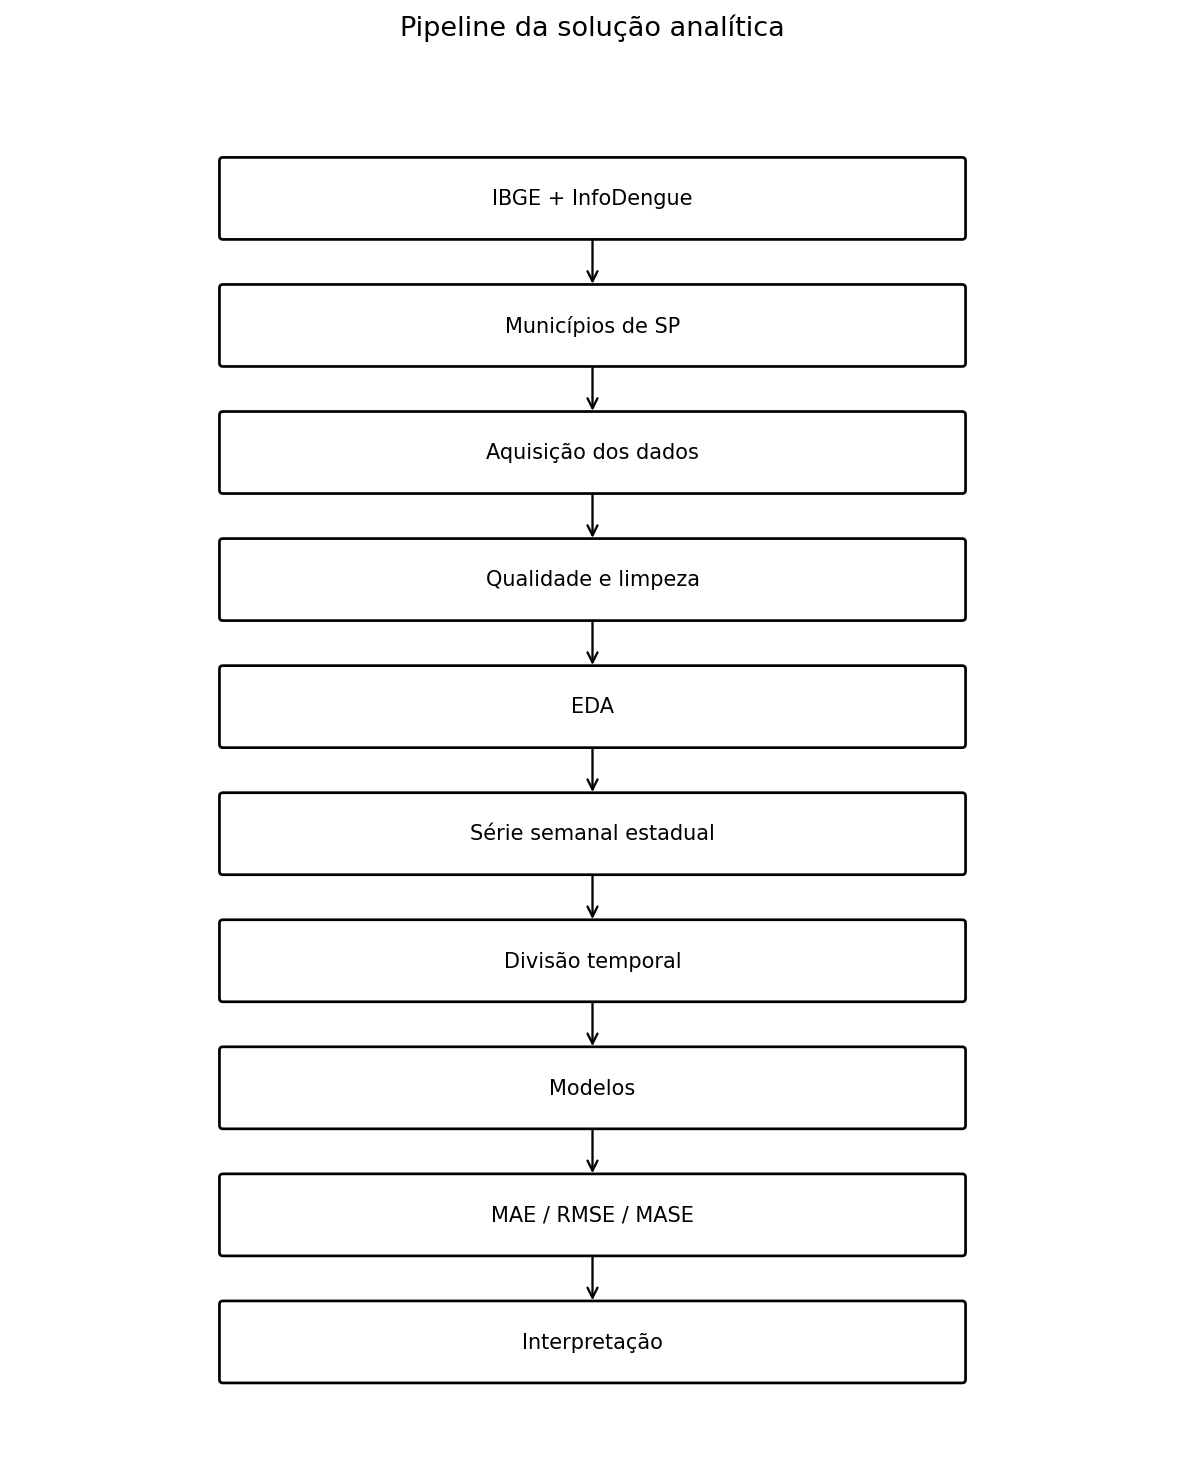

O diagrama representa o fluxo adotado no projeto. A identificação dos municípios é obtida a partir do IBGE e os registros epidemiológicos são consultados no InfoDengue. O recorte considera apenas o estado de São Paulo. Após a aquisição, são verificadas qualidade, consistência temporal, valores ausentes e duplicidades. Em seguida são realizadas as etapas de pré-processamento e Análise Exploratória de Dados (EDA). Para a modelagem parcial, os registros municipais são agregados por semana, formando uma série temporal estadual. A série é dividida cronologicamente em treinamento, validação e teste, evitando vazamento de informações futuras. Os modelos são avaliados por MAE, RMSE e MASE e, por fim, os resultados são comparados e interpretados.


# **EDA e Pré-processamento dos dados**

A análise utiliza exclusivamente registros dos municípios do estado de São Paulo. A base é obtida pelo InfoDengue e pode ser gerada previamente pelo notebook `base.extração.ipynb`, mantido na mesma pasta. Para tornar o notebook principal reproduzível, a célula abaixo também contém uma rotina de aquisição automática: caso o arquivo CSV ainda não exista, os dados são coletados diretamente das APIs do IBGE e InfoDengue.

O pré-processamento contempla conversão da variável temporal, remoção de duplicidades por município e data, verificação de valores ausentes e negativos, ordenação cronológica e construção de uma série semanal agregada do estado. A EDA apresenta dimensões da base, período analisado, número de municípios, estatísticas descritivas, evolução temporal, distribuição dos casos, sazonalidade e correlações entre a variável-alvo e atributos climáticos disponíveis.

**Recorte e simplificação adotados:** nesta entrega parcial, a primeira rodada de modelagem utiliza a soma semanal dos casos dos municípios paulistas para representar o estado de São Paulo. A base original permanece em granularidade município × semana e poderá ser utilizada na etapa final para análises municipais ou regionais.


CSV não encontrado. Iniciando extração automática...
Municípios selecionados (SP): 645


Consultando municípios de SP:   0%|          | 0/645 [00:00<?, ?it/s]

Extração concluída em 7.4 minutos.


C:\Users\pedro\AppData\Local\Temp\ipykernel_14428\1446729925.py:118: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df["data_iniSE"] = pd.to_datetime(df["data_iniSE"], errors="coerce", dayfirst=True)


Base salva em: C:\Users\pedro\OneDrive\Área de Trabalho\5º Semestre\Projeto Aplicado IV\A3\Projeto_Aplicado_IV_TEMPLATE_EXATO_VSCode\Base_Dengue_SP_2020_ate_hoje.csv

CARACTERIZAÇÃO DA BASE
Linhas: 228.975
Colunas: 32
Período: 2019-12-29 a 2026-10-11
Municípios: 645
Duplicidades removidas: 0


...


VARIÁVEIS COM VALORES NEGATIVOS


,informacao
0,Nenhum valor negativo encontrado nas colunas n...



ESTATÍSTICAS DESCRITIVAS


,count,mean,std,min,25%,50%,75%,max
casos,228975.0,37.393755,615.499332,0.000000,0.000000,1.000000,10.000000,8.538900e+04
casos_est,228975.0,37.413958,615.508907,0.000000,0.000000,1.000000,10.000000,8.538900e+04
casos_est_min,228975.0,37.397825,615.501947,0.000000,0.000000,1.000000,10.000000,8.538900e+04
casos_est_max,228925.0,30.833216,184.135371,0.000000,0.000000,1.000000,10.000000,9.950000e+03
Rt,228975.0,1.311887,2.978431,0.000000,0.000000,0.604525,1.285834,1.852162e+01
p_rt1,228975.0,0.344556,0.374467,0.000000,0.000000,0.182875,0.695956,1.000000e+00
p_inc100k,228975.0,67.529363,190.215904,0.000000,0.000000,7.132668,43.833214,6.149560e+03
pop,228975.0,71543.551859,495678.476750,838.000000,5604.000000,13615.000000,40828.000000,1.232523e+07
tempmin,228975.0,18.391418,3.512535,4.142857,16.000000,18.714286,21.000000,3.383333e+01
tempmed,224272.0,22.655006,3.408121,11.014243,20.375868,22.912814,25.120121,3.516667e+01



Semanas ausentes na série estadual (casos_est): 0


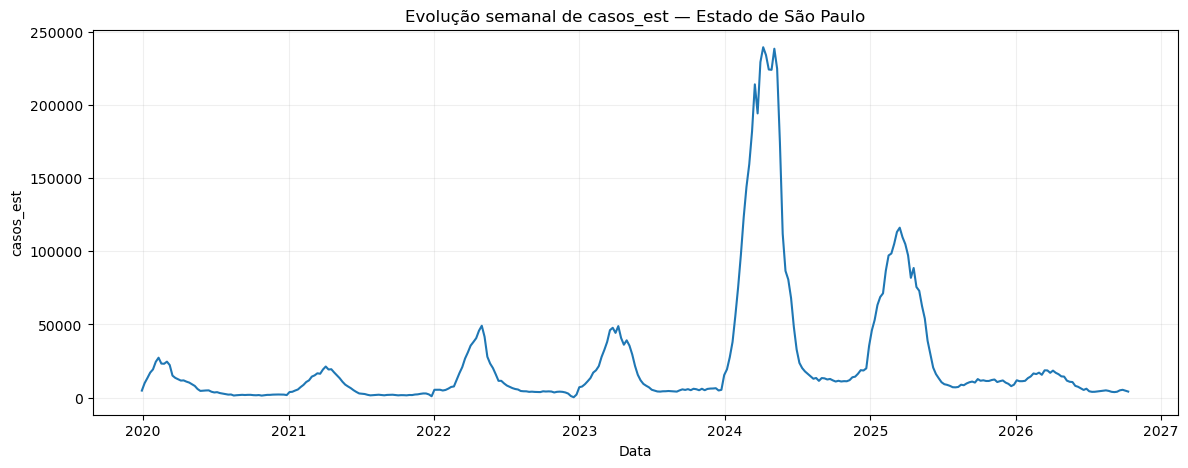

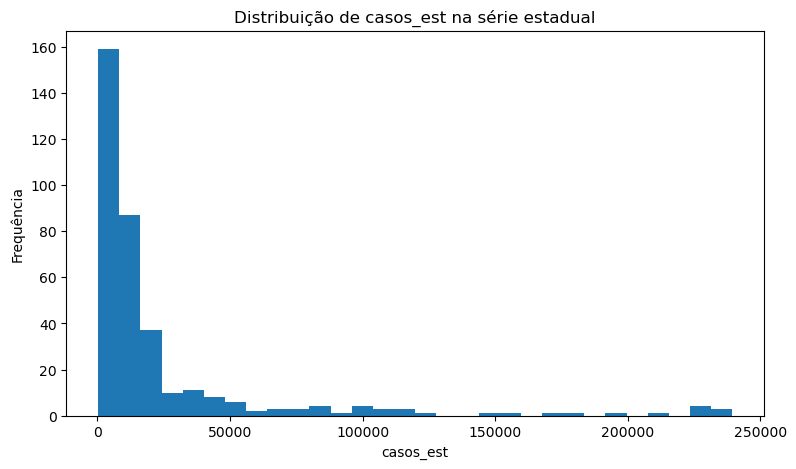

Possíveis outliers pelo critério IQR: 49 de 355 observações.
Os picos não são removidos automaticamente porque podem representar surtos epidemiológicos reais.


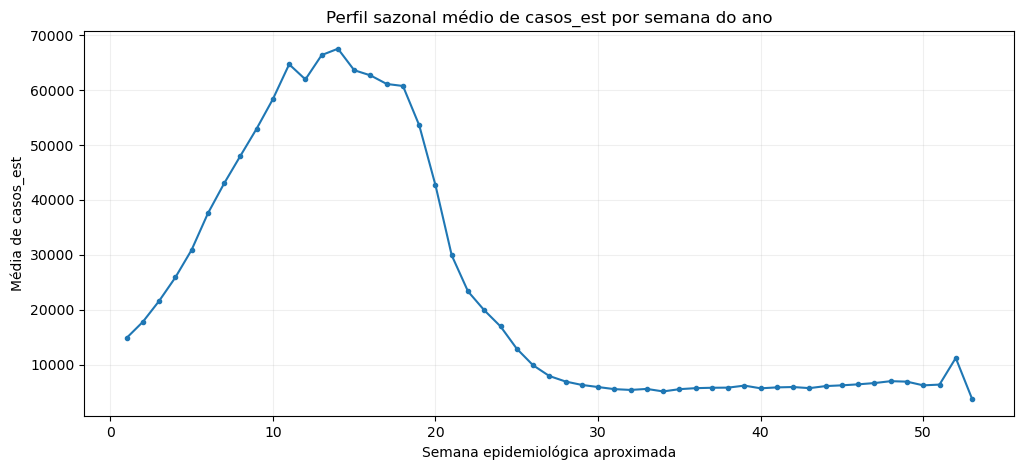


CORRELAÇÕES COM A VARIÁVEL-ALVO


,correlacao
casos_est,1.000000
p_inc100k,0.887934
p_rt1,0.459353
tempmin,0.197926
tempmed,0.156242
umidmed,0.151934
umidmax,0.144442
umidmin,0.125306
tempmax,0.093303
Rt,0.037666



Pré-processamento concluído. A variável-alvo definida foi: casos_est


In [1]:
# ============================================================
# EDA E PRÉ-PROCESSAMENTO
# ============================================================
# Caso necessário, instale as dependências uma única vez no ambiente:
# %pip install pandas numpy matplotlib scikit-learn statsmodels requests tqdm

from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm
import io
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ---------------------------
# Configurações
# ---------------------------
ANO_INICIAL = 2020
ANO_FINAL = pd.Timestamp.today().year
DATA_HOJE = pd.Timestamp.today().normalize()
UF_ALVO = "SP"
MAX_WORKERS = 8
ARQUIVO_FINAL = Path("Base_Dengue_SP_2020_ate_hoje.csv")
API_IBGE = "https://servicodados.ibge.gov.br/api/v1/localidades/municipios"
API_INFODENGUE = "https://info.dengue.mat.br/api/alertcity"


def extrair_dados_sp():
    """Extrai dados semanais de dengue de todos os municípios de SP."""
    resposta_ibge = requests.get(API_IBGE, timeout=60)
    resposta_ibge.raise_for_status()

    municipios = []
    for municipio in resposta_ibge.json():
        try:
            uf = municipio["microrregiao"]["mesorregiao"]["UF"]["sigla"]
            if uf == UF_ALVO:
                municipios.append({
                    "geocode": int(municipio["id"]),
                    "municipio_nome": municipio["nome"],
                    "UF": uf,
                })
        except Exception:
            continue

    df_municipios = pd.DataFrame(municipios).drop_duplicates("geocode")
    print(f"Municípios selecionados ({UF_ALVO}): {len(df_municipios)}")

    def consultar(registro):
        frames = []
        for ano in range(ANO_INICIAL, ANO_FINAL + 1):
            params = {
                "geocode": registro["geocode"],
                "disease": "dengue",
                "format": "csv",
                "ew_start": 1,
                "ew_end": 53,
                "ey_start": ano,
                "ey_end": ano,
            }
            try:
                r = requests.get(API_INFODENGUE, params=params, timeout=90)
                if r.status_code != 200 or not r.text.strip() or r.text.startswith("[EE]"):
                    continue
                dados = pd.read_csv(io.StringIO(r.text))
                if dados.empty:
                    continue
                dados["geocode"] = registro["geocode"]
                dados["municipio_nome"] = registro["municipio_nome"]
                dados["UF"] = registro["UF"]
                frames.append(dados)
            except Exception:
                continue
        return pd.concat(frames, ignore_index=True) if frames else None

    registros = df_municipios.to_dict("records")
    frames = []
    inicio = time.time()
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        tarefas = {executor.submit(consultar, r): r for r in registros}
        for tarefa in tqdm(as_completed(tarefas), total=len(tarefas), desc="Consultando municípios de SP"):
            resultado = tarefa.result()
            if resultado is not None and not resultado.empty:
                frames.append(resultado)

    if not frames:
        raise RuntimeError("A API do InfoDengue não retornou dados para os municípios selecionados.")

    df = pd.concat(frames, ignore_index=True)
    print(f"Extração concluída em {(time.time()-inicio)/60:.1f} minutos.")
    return df


# ---------------------------
# Carregamento / aquisição
# ---------------------------
if ARQUIVO_FINAL.exists():
    df_raw = pd.read_csv(ARQUIVO_FINAL)
    print(f"Base carregada: {ARQUIVO_FINAL}")
else:
    print("CSV não encontrado. Iniciando extração automática...")
    df_raw = extrair_dados_sp()

# Normaliza o nome da coluna temporal, se necessário
if "data_ini_SE" in df_raw.columns and "data_iniSE" not in df_raw.columns:
    df_raw = df_raw.rename(columns={"data_ini_SE": "data_iniSE"})

if "data_iniSE" not in df_raw.columns:
    raise KeyError("A base precisa conter a coluna temporal 'data_iniSE' ou 'data_ini_SE'.")

# ---------------------------
# Pré-processamento
# ---------------------------
df = df_raw.copy()
df["data_iniSE"] = pd.to_datetime(df["data_iniSE"], errors="coerce", dayfirst=True)
df = df[df["data_iniSE"].notna()].copy()
df = df[df["data_iniSE"] <= DATA_HOJE].copy()

# Garante recorte de SP caso um CSV nacional seja usado por engano
if "UF" in df.columns:
    df = df[df["UF"].astype(str).str.upper().eq("SP")].copy()

# Duplicidade mais segura: município + data
chave_dup = [c for c in ["geocode", "data_iniSE"] if c in df.columns]
if len(chave_dup) == 2:
    duplicados_antes = int(df.duplicated(subset=chave_dup).sum())
    df = df.drop_duplicates(subset=chave_dup, keep="last")
else:
    duplicados_antes = int(df.duplicated().sum())
    df = df.drop_duplicates()

df = df.sort_values([c for c in ["municipio_nome", "data_iniSE"] if c in df.columns]).reset_index(drop=True)

# Salva a versão tratada para reutilização
if not ARQUIVO_FINAL.exists():
    df.to_csv(ARQUIVO_FINAL, index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
    print(f"Base salva em: {ARQUIVO_FINAL.resolve()}")

# ---------------------------
# Caracterização inicial
# ---------------------------
print("\nCARACTERIZAÇÃO DA BASE")
print("Linhas:", f"{len(df):,}".replace(",", "."))
print("Colunas:", df.shape[1])
print("Período:", df["data_iniSE"].min().date(), "a", df["data_iniSE"].max().date())
if "municipio_nome" in df.columns:
    print("Municípios:", df["municipio_nome"].nunique())
print("Duplicidades removidas:", duplicados_antes)

display(df.head())

print("\nTIPOS DAS VARIÁVEIS")
display(df.dtypes.rename("tipo").to_frame())

# ---------------------------
# Qualidade dos dados
# ---------------------------
qualidade = pd.DataFrame({
    "nulos": df.isna().sum(),
    "percentual_nulos": (df.isna().mean() * 100).round(2),
    "unicos": df.nunique(dropna=True),
}).sort_values("percentual_nulos", ascending=False)
print("\nQUALIDADE DOS DADOS")
display(qualidade)

numericas = df.select_dtypes(include=np.number).columns
negativos = pd.Series({c: int((df[c] < 0).sum()) for c in numericas}, name="valores_negativos")
negativos = negativos[negativos > 0].sort_values(ascending=False)
print("\nVARIÁVEIS COM VALORES NEGATIVOS")
display(negativos.to_frame() if len(negativos) else pd.DataFrame({"informacao": ["Nenhum valor negativo encontrado nas colunas numéricas."]}))

# ---------------------------
# Estatísticas descritivas
# ---------------------------
colunas_interesse = [c for c in [
    "casos", "casos_est", "casos_est_min", "casos_est_max", "Rt", "p_rt1",
    "p_inc100k", "pop", "tempmin", "tempmed", "tempmax", "umidmin", "umidmed", "umidmax"
] if c in df.columns]
print("\nESTATÍSTICAS DESCRITIVAS")
display(df[colunas_interesse].describe().T if colunas_interesse else df.describe(include="all").T)

# ---------------------------
# Construção da série estadual
# ---------------------------
TARGET = "casos_est" if "casos_est" in df.columns else "casos"
if TARGET not in df.columns:
    raise KeyError("Não foi encontrada a variável 'casos_est' nem 'casos'.")

# Soma para variáveis de contagem; média para variáveis climáticas/índices
soma_cols = [c for c in ["casos", "casos_est"] if c in df.columns]
media_cols = [c for c in ["tempmin", "tempmed", "tempmax", "umidmin", "umidmed", "umidmax", "Rt", "p_rt1", "p_inc100k"] if c in df.columns]
agg = {c: "sum" for c in soma_cols}
agg.update({c: "mean" for c in media_cols})

serie_sp = df.groupby("data_iniSE").agg(agg).sort_index()
indice_completo = pd.date_range(serie_sp.index.min(), serie_sp.index.max(), freq="W-SUN")
serie_sp = serie_sp.reindex(indice_completo)
serie_sp.index.name = "data_iniSE"

faltas_target = int(serie_sp[TARGET].isna().sum())
print(f"\nSemanas ausentes na série estadual ({TARGET}):", faltas_target)

# Interpolação apenas para lacunas temporais, necessária para alguns modelos
serie_modelo = serie_sp.copy()
serie_modelo[TARGET] = serie_modelo[TARGET].interpolate(method="time").ffill().bfill()
for c in media_cols:
    if c in serie_modelo.columns:
        serie_modelo[c] = serie_modelo[c].interpolate(method="time").ffill().bfill()

# ---------------------------
# EDA gráfica
# ---------------------------
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(serie_sp.index, serie_sp[TARGET])
ax.set_title(f"Evolução semanal de {TARGET} — Estado de São Paulo")
ax.set_xlabel("Data")
ax.set_ylabel(TARGET)
ax.grid(alpha=0.2)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(serie_sp[TARGET].dropna(), bins=30)
ax.set_title(f"Distribuição de {TARGET} na série estadual")
ax.set_xlabel(TARGET)
ax.set_ylabel("Frequência")
plt.show()

# Outliers por regra do IQR — usados apenas para diagnóstico; não são removidos automaticamente
y = serie_sp[TARGET].dropna()
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5*iqr, q3 + 1.5*iqr
n_outliers = int(((y < lim_inf) | (y > lim_sup)).sum())
print(f"Possíveis outliers pelo critério IQR: {n_outliers} de {len(y)} observações.")
print("Os picos não são removidos automaticamente porque podem representar surtos epidemiológicos reais.")

# Perfil sazonal médio
sazonal = serie_sp[[TARGET]].dropna().copy()
sazonal["semana_ano"] = sazonal.index.isocalendar().week.astype(int)
perfil = sazonal.groupby("semana_ano")[TARGET].mean()
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(perfil.index, perfil.values, marker="o", markersize=3)
ax.set_title(f"Perfil sazonal médio de {TARGET} por semana do ano")
ax.set_xlabel("Semana epidemiológica aproximada")
ax.set_ylabel(f"Média de {TARGET}")
ax.grid(alpha=0.2)
plt.show()

# Correlações com variáveis disponíveis
corr_cols = [c for c in [TARGET, "tempmin", "tempmed", "tempmax", "umidmin", "umidmed", "umidmax", "Rt", "p_rt1", "p_inc100k"] if c in serie_modelo.columns]
if len(corr_cols) > 1:
    correlacoes = serie_modelo[corr_cols].corr(numeric_only=True)[TARGET].sort_values(ascending=False)
    print("\nCORRELAÇÕES COM A VARIÁVEL-ALVO")
    display(correlacoes.to_frame("correlacao"))

print("\nPré-processamento concluído. A variável-alvo definida foi:", TARGET)


# **Modelos**

A modelagem foi estruturada para comparar abordagens com diferentes níveis de complexidade. O primeiro método é um **Seasonal Naive**, utilizado como referência mínima: a previsão de uma semana é dada pelo valor observado aproximadamente 52 semanas antes. O segundo método é o **Seasonal AutoRegressive Integrated Moving Average (SARIMA)**, adequado a séries temporais com dependência e sazonalidade. O terceiro é um **Random Forest Regressor**, que transforma a série temporal em um problema supervisionado por meio de variáveis defasadas (*lags*), médias móveis e, quando disponíveis, atributos climáticos.

A divisão dos dados é cronológica, preservando a ordem temporal. São utilizados aproximadamente 70% dos registros para treinamento, 15% para validação e 15% para teste. O conjunto de teste permanece totalmente fora do ajuste dos modelos. As métricas utilizadas são Erro Absoluto Médio (MAE), Raiz do Erro Quadrático Médio (RMSE) e Erro Absoluto Escalado Médio (MASE). Valores menores indicam melhor desempenho. Para MASE, valores abaixo de 1 indicam desempenho superior ao método sazonal ingênuo utilizado como escala.


Treino: 2019-12-29 a 2024-09-22 (248 semanas)
Validação: 2024-09-29 a 2025-09-28 (53 semanas)
Teste: 2025-10-05 a 2026-10-11 (54 semanas)

RESULTADOS NO CONJUNTO DE TESTE


,Modelo,MAE,RMSE,MASE,N_teste
0,Random Forest com lags,888.312,1225.269,0.030,54
1,Seasonal Naive (52 semanas),29656.500,43873.340,1.238,54
2,"SARIMA (1,1,1)x(1,1,0,52)",62370.266,92730.042,2.604,54


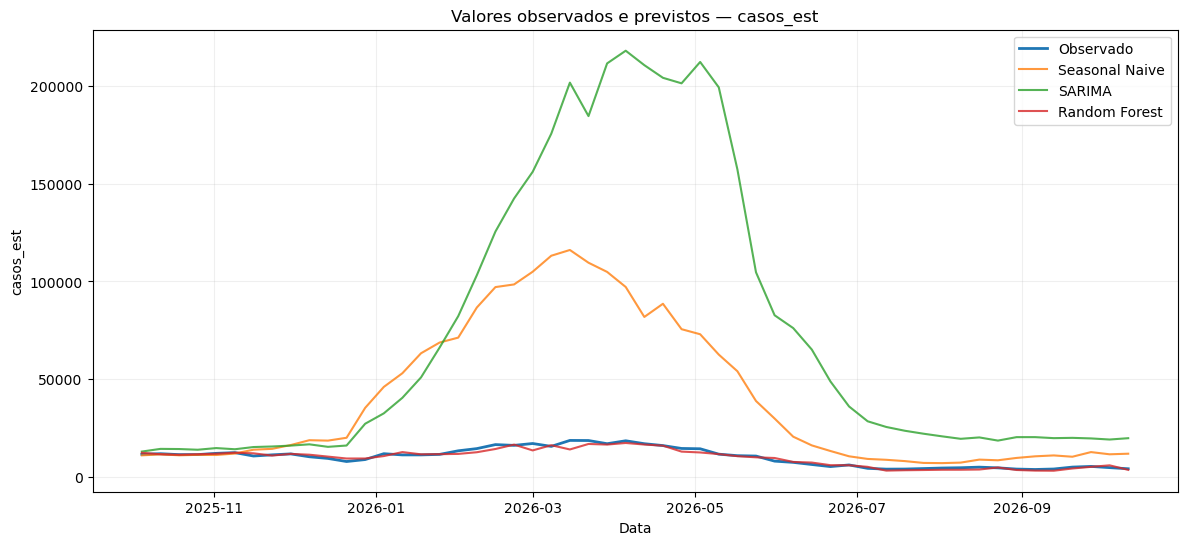

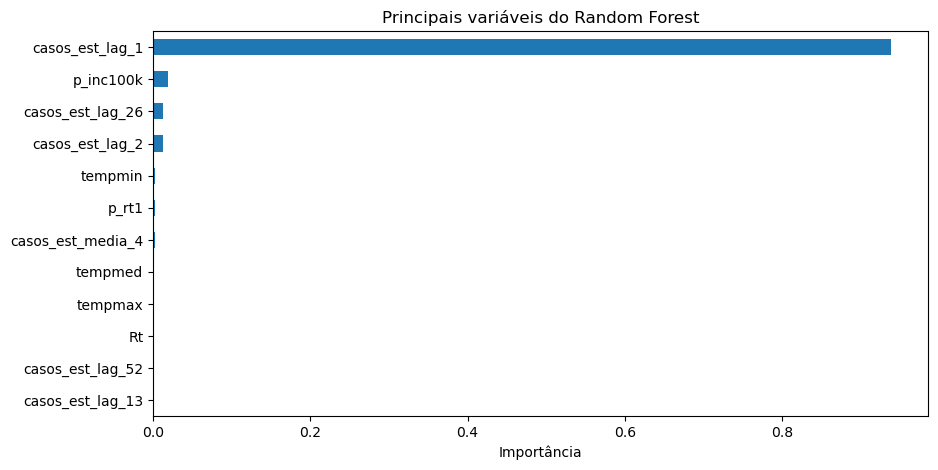


### Interpretação parcial dos resultados

No conjunto de teste, o modelo com menor MAE foi **Random Forest com lags**, com **MAE = 888.312**, **RMSE = 1225.269** e **MASE = 0.030**. A comparação deve ser interpretada em conjunto com o gráfico de valores observados e previstos. O resultado é parcial e corresponde ao recorte estadual adotado nesta etapa. Na etapa final, os hiperparâmetros poderão ser refinados e a análise poderá ser expandida para granularidade municipal ou regional.


In [2]:
# ============================================================
# MODELAGEM, VALIDAÇÃO E RESULTADOS
# ============================================================
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX
from IPython.display import Markdown, display
import warnings
warnings.filterwarnings("ignore")

# ---------------------------
# Preparação temporal
# ---------------------------
model_data = serie_modelo[[TARGET] + [c for c in ["tempmin", "tempmed", "tempmax", "umidmin", "umidmed", "umidmax", "Rt", "p_rt1", "p_inc100k"] if c in serie_modelo.columns]].copy()
model_data = model_data.dropna(subset=[TARGET])

n = len(model_data)
if n < 120:
    raise ValueError(f"A série possui apenas {n} semanas. Recomenda-se ampliar o período para modelagem sazonal anual.")

fim_treino = int(n * 0.70)
fim_validacao = int(n * 0.85)
train = model_data.iloc[:fim_treino].copy()
valid = model_data.iloc[fim_treino:fim_validacao].copy()
test = model_data.iloc[fim_validacao:].copy()
train_val = model_data.iloc[:fim_validacao].copy()

print("Treino:", train.index.min().date(), "a", train.index.max().date(), f"({len(train)} semanas)")
print("Validação:", valid.index.min().date(), "a", valid.index.max().date(), f"({len(valid)} semanas)")
print("Teste:", test.index.min().date(), "a", test.index.max().date(), f"({len(test)} semanas)")


def mase(y_true, y_pred, y_insample, m=52):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    y_insample = np.asarray(y_insample, dtype=float)
    if len(y_insample) > m:
        escala = np.mean(np.abs(y_insample[m:] - y_insample[:-m]))
    else:
        escala = np.mean(np.abs(np.diff(y_insample)))
    if escala == 0 or np.isnan(escala):
        return np.nan
    return np.mean(np.abs(y_true - y_pred)) / escala


def avaliar(nome, y_true, y_pred, y_insample):
    pares = pd.DataFrame({"real": y_true, "pred": y_pred}).dropna()
    return {
        "Modelo": nome,
        "MAE": mean_absolute_error(pares["real"], pares["pred"]),
        "RMSE": np.sqrt(mean_squared_error(pares["real"], pares["pred"])),
        "MASE": mase(pares["real"].values, pares["pred"].values, y_insample, m=52),
        "N_teste": len(pares),
    }

# ---------------------------
# 1) Seasonal Naive
# ---------------------------
pred_naive = model_data[TARGET].shift(52).reindex(test.index)
resultado_naive = avaliar("Seasonal Naive (52 semanas)", test[TARGET], pred_naive, train_val[TARGET])

# ---------------------------
# 2) SARIMA
# ---------------------------
# Configuração inicial simples e reproduzível; poderá ser refinada na Etapa 4.
sarima = SARIMAX(
    train_val[TARGET],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 0, 52),
    enforce_stationarity=False,
    enforce_invertibility=False,
)
sarima_fit = sarima.fit(disp=False, maxiter=200)
pred_sarima = sarima_fit.get_forecast(steps=len(test)).predicted_mean
pred_sarima.index = test.index
resultado_sarima = avaliar("SARIMA (1,1,1)x(1,1,0,52)", test[TARGET], pred_sarima, train_val[TARGET])

# ---------------------------
# 3) Random Forest com lags
# ---------------------------
def criar_features(base, target):
    dados = base.copy()
    for lag in [1, 2, 4, 8, 13, 26, 52]:
        dados[f"{target}_lag_{lag}"] = dados[target].shift(lag)
    dados[f"{target}_media_4"] = dados[target].shift(1).rolling(4).mean()
    dados[f"{target}_media_13"] = dados[target].shift(1).rolling(13).mean()
    dados["semana_ano"] = dados.index.isocalendar().week.astype(int)
    dados["mes"] = dados.index.month
    return dados.dropna()

ml = criar_features(model_data, TARGET)
features = [c for c in ml.columns if c != TARGET]
X = ml[features]
y_ml = ml[TARGET]

# Usa exatamente o início do teste temporal definido acima
X_train_rf = X[X.index < test.index.min()]
y_train_rf = y_ml[y_ml.index < test.index.min()]
X_test_rf = X[X.index >= test.index.min()]
y_test_rf = y_ml[y_ml.index >= test.index.min()]

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
)
rf.fit(X_train_rf, y_train_rf)
pred_rf = pd.Series(rf.predict(X_test_rf), index=X_test_rf.index)
resultado_rf = avaliar("Random Forest com lags", y_test_rf, pred_rf, y_train_rf)

# ---------------------------
# Tabela comparativa
# ---------------------------
resultados = pd.DataFrame([resultado_naive, resultado_sarima, resultado_rf]).sort_values("MAE").reset_index(drop=True)
for c in ["MAE", "RMSE", "MASE"]:
    resultados[c] = resultados[c].round(3)

print("\nRESULTADOS NO CONJUNTO DE TESTE")
display(resultados)

# ---------------------------
# Gráfico observado x previsto
# ---------------------------
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(test.index, test[TARGET], label="Observado", linewidth=2)
ax.plot(pred_naive.index, pred_naive, label="Seasonal Naive", alpha=0.8)
ax.plot(pred_sarima.index, pred_sarima, label="SARIMA", alpha=0.8)
ax.plot(pred_rf.index, pred_rf, label="Random Forest", alpha=0.8)
ax.set_title(f"Valores observados e previstos — {TARGET}")
ax.set_xlabel("Data")
ax.set_ylabel(TARGET)
ax.legend()
ax.grid(alpha=0.2)
plt.show()

# Importância de variáveis do RF
importancias = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(10, 5))
importancias.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Principais variáveis do Random Forest")
ax.set_xlabel("Importância")
plt.show()

# Interpretação automática, baseada nos resultados efetivamente calculados
melhor = resultados.iloc[0]
texto = f"""
### Interpretação parcial dos resultados

No conjunto de teste, o modelo com menor MAE foi **{melhor['Modelo']}**, com **MAE = {melhor['MAE']:.3f}**, **RMSE = {melhor['RMSE']:.3f}** e **MASE = {melhor['MASE']:.3f}**. A comparação deve ser interpretada em conjunto com o gráfico de valores observados e previstos. O resultado é parcial e corresponde ao recorte estadual adotado nesta etapa. Na etapa final, os hiperparâmetros poderão ser refinados e a análise poderá ser expandida para granularidade municipal ou regional.
"""
display(Markdown(texto))


# **Resultados**

A célula de modelagem apresenta automaticamente a tabela comparativa de MAE, RMSE e MASE para os modelos Seasonal Naive, SARIMA e Random Forest, além do gráfico de valores observados e previstos. Como os valores dependem da execução sobre a versão mais recente da base do InfoDengue, eles não são fixados manualmente neste texto. A interpretação parcial também é gerada automaticamente a partir do modelo que obtiver o menor MAE no conjunto de teste.

A análise dos resultados deve considerar que o Seasonal Naive funciona como referência mínima para uma série semanal sazonal, enquanto SARIMA representa uma abordagem estatística e Random Forest representa uma abordagem de Aprendizado de Máquina baseada em atributos temporais. A comparação permite verificar se o aumento da complexidade se traduz em redução efetiva do erro de previsão.

## Cronograma atualizado

| Período | Atividade restante | Situação |
|---|---|---|
| 27/10 a 02/11 | Revisão dos modelos testados e correções da base | Planejado |
| 03/11 a 09/11 | Análise crítica e refinamento de hiperparâmetros | Planejado |
| 10/11 a 15/11 | Discussão e seleção do modelo final | Planejado |
| 16/11 a 20/11 | Proposição de melhorias e expansão da análise | Planejado |
| 21/11 a 24/11 | Preparação do produto analítico | Planejado |
| 25/11 a 26/11 | Documentação final e organização dos artefatos | Planejado |
| 28/11 a 29/11 | Revisão e preparação da apresentação | Planejado |
| 30/11 | Entrega final | Planejado |


# **Dicussão e Conclusão**

Nesta etapa foi estruturado um pipeline reproduzível para aquisição, preparação, exploração e modelagem dos dados de dengue do estado de São Paulo. O recorte estadual reduziu o escopo inicial e permitiu construir uma primeira prova de conceito de previsão semanal, preservando a base municipal para aprofundamentos posteriores.

A EDA foi utilizada para avaliar qualidade, completude, distribuição, picos e comportamento sazonal. Os possíveis outliers não foram removidos automaticamente, pois valores extremos podem corresponder a surtos epidemiológicos reais. A divisão cronológica entre treinamento, validação e teste reduz o risco de vazamento de informações futuras.

A comparação entre um modelo sazonal simples, SARIMA e Random Forest permite avaliar abordagens com diferentes pressupostos. O resultado quantitativo efetivo é apresentado pela execução da célula anterior e deve orientar o refinamento da Etapa 4. A escolha do modelo final não deve considerar apenas uma métrica isolada, mas também estabilidade dos erros, capacidade de acompanhar picos, interpretabilidade e custo de manutenção.

Como limitações, destacam-se a agregação estadual utilizada nesta etapa, a possibilidade de revisões retrospectivas dos registros do InfoDengue, eventuais dados ausentes e a heterogeneidade entre municípios. Como trabalhos futuros, recomenda-se refinar hiperparâmetros, testar modelos com variáveis exógenas, aplicar validação temporal em múltiplas janelas e avaliar previsões em granularidade municipal ou regional. Dessa forma, o projeto permanece alinhado ao objetivo de transformar dados epidemiológicos e climáticos em informações potencialmente úteis ao planejamento preventivo de saúde pública.


# **Apresentação**

Inserir nesta seção, antes da entrega final, o link público ou não listado do vídeo de apresentação com apoio de slides.

**Link do vídeo:** _a inserir_


# **Referências**

BOX, G. E. P.; JENKINS, G. M. *Time Series Analysis: Forecasting and Control*. San Francisco: Holden-Day, 1976.

HYNDMAN, R. J.; ATHANASOPOULOS, G. *Forecasting: Principles and Practice*. 3. ed. Melbourne: OTexts, 2021.

INFODENGUE. **API: acesso aos dados epidemiológicos**. Disponível em: <https://info.dengue.mat.br>. Acesso em: 20 ago. 2026.

INSTITUTO BRASILEIRO DE GEOGRAFIA E ESTATÍSTICA (IBGE). **API de localidades**. Disponível em: <https://servicodados.ibge.gov.br/api/docs/localidades>. Acesso em: 26 out. 2026.

RUMELHART, D. E. et al. Learning representations by back-propagating errors. *Nature*, v. 323, p. 533–536, 1986.

ZHANG, G. P. Time series forecasting using a hybrid ARIMA and neural network model. *Neurocomputing*, v. 50, p. 159–175, 2003.
